# 🛡️ SentinelPay — Real-Time Anomaly Detection in Financial Transactions
**Case study:** SecurePay FinTech · **Approach:** unsupervised (Isolation Forest + Local Outlier Factor) · **Stack:** pandas, scikit-learn, matplotlib

> Fraud is < 0.2 % of traffic, so a classifier that always answers *"legitimate"* is 99.8 % accurate and completely useless.
> Instead of learning what fraud looks like (it keeps changing), we learn what **normal** looks like and flag deviations.

**Notebook map** — Phase 1 data & EDA → Phase 2 models → Phase 3 evaluation & threshold tuning → Recommendation → GenAI analyst.

In [1]:
import sys, time, warnings
sys.path.insert(0, "..")                      # make the `sentinelpay` package importable
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.metrics import average_precision_score

from sentinelpay import viz
from sentinelpay.config import PipelineConfig
from sentinelpay.data import load_data, eda_summary, preprocess, feature_separation
from sentinelpay.pipeline import run_pipeline
pd.set_option("display.precision", 3)
cfg = PipelineConfig()

## Phase 1 — Data analysis & preprocessing
### 1.1 Load
`load_data` reads `data/creditcard.csv` (the public ULB / Kaggle dataset) when present; otherwise it generates a
**synthetic ULB-style dataset** with the same schema (`Time`, `V1…V28`, `Amount`, `Class`) so the project runs anywhere.

In [2]:
df, source = load_data(cfg.data_path, cfg.n_samples, cfg.fraud_rate, cfg.seed)
print("Source:", source, "| shape:", df.shape)
df.head()

Source: Synthetic demo data (ULB-style) | shape: (100000, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,2.0,2.222,-1.001,-0.127,0.853,-1.529,-1.183,-0.135,0.226,1.090,-1.988,-0.131,-0.169,0.365,-2.516,-0.542,0.592,-0.008,-0.342,-0.440,-0.462,0.130,0.034,-0.012,-0.402,-0.197,0.323,0.334,-0.363,696.37,0
1,2.0,-0.769,1.384,1.388,0.929,-0.440,1.227,-2.050,0.693,1.684,-1.761,0.985,-3.550,1.919,-0.256,0.311,-0.087,0.086,-0.184,0.239,0.067,-0.656,-0.071,0.276,0.355,0.283,-0.138,0.222,-0.067,9.60,0
2,3.0,-1.197,0.043,-1.875,-1.086,-2.164,-0.985,0.660,-0.341,0.385,-0.390,-0.835,0.974,-0.941,-0.007,-0.254,0.460,-0.434,-0.803,-0.081,0.474,0.256,-0.316,0.392,-0.577,-0.033,-0.731,-0.283,-0.280,30.87,0
3,3.0,-1.998,-0.257,-3.646,-2.811,-0.693,-0.517,1.478,0.429,0.529,0.375,-1.641,-0.503,0.546,-0.329,0.194,-0.575,-0.225,-0.052,0.938,0.268,0.072,0.374,-0.030,0.629,0.391,-0.058,0.319,0.674,46.99,0
4,4.0,0.103,0.262,-1.316,-1.506,2.229,-1.574,0.273,0.152,0.871,-0.717,0.358,-0.549,-0.894,0.947,0.669,-0.375,0.148,0.334,0.915,-0.947,0.069,-0.036,-0.231,0.002,0.168,0.541,-0.283,0.220,15.64,0


In [3]:
eda = eda_summary(df)
pd.Series({k: (f"{v:,.4f}" if isinstance(v, float) else f"{v:,}") for k, v in eda.items()}, name="value").to_frame()

,value
n_transactions,"100,000"
n_fraud,300
n_normal,"99,700"
fraud_rate,0.0030
imbalance_ratio,332.3333
amount_mean,55.6350
amount_median,22.2500
amount_max,"5,619.4700"
amount_skew,11.5563
fraud_amount_median,30.6150


### 1.2 The class imbalance — and the accuracy trap

A model that predicts 'legitimate' for everything scores 99.70% accuracy and catches 0 fraud.


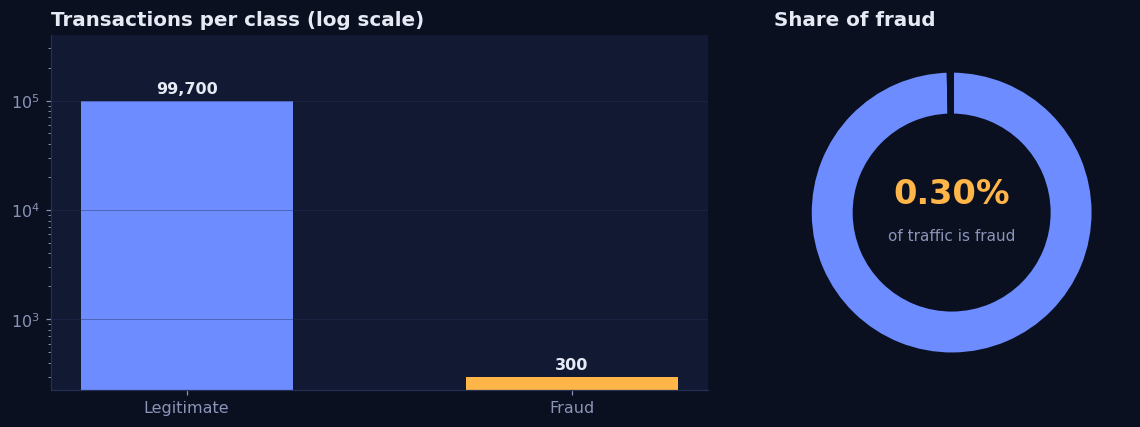

In [4]:
viz.plot_class_imbalance(df); plt.show()
print(f"A model that predicts 'legitimate' for everything scores {eda['naive_accuracy']:.2%} accuracy and catches 0 fraud.")

### 1.3 Distribution of `Amount` and `Time`

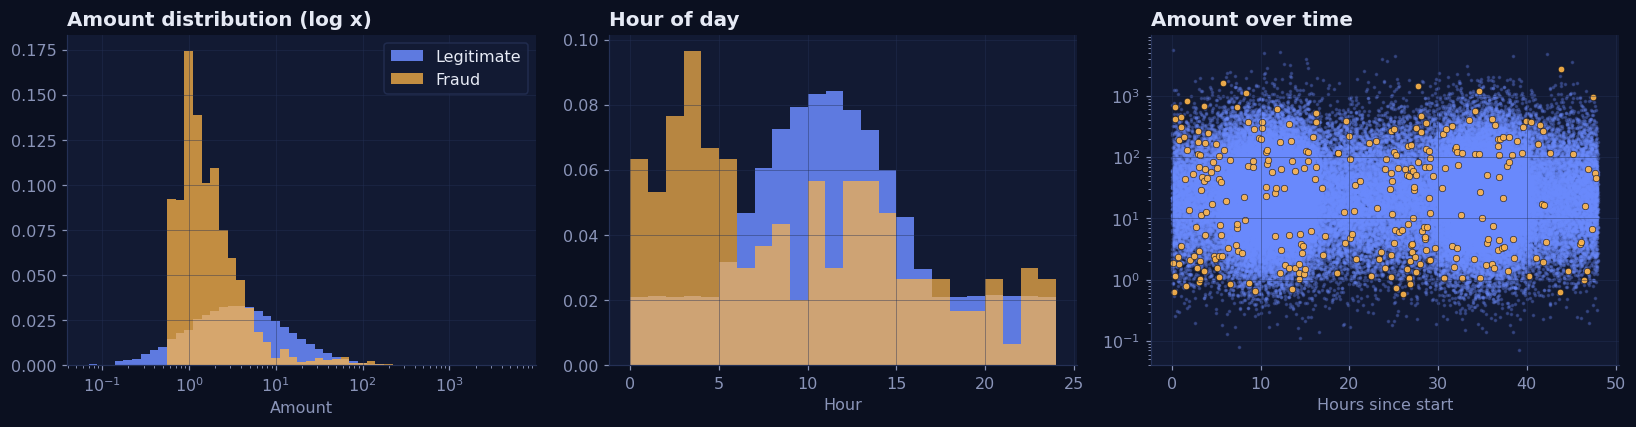

In [5]:
viz.plot_amount_time(df); plt.show()

**Observations.** Amounts are extremely right-skewed (a handful of very large purchases), time follows a day/night cycle,
and fraud shows two behaviours: tiny "card-testing" amounts and larger purchases, with a skew towards night hours.

### 1.4 Advanced scaling — `RobustScaler` instead of `StandardScaler`
Distance-based models (LOF) are wrecked by outliers. `StandardScaler` uses mean/σ, which the extreme purchases drag around;
`RobustScaler` uses **median and IQR**: `x' = (x − median) / IQR`.

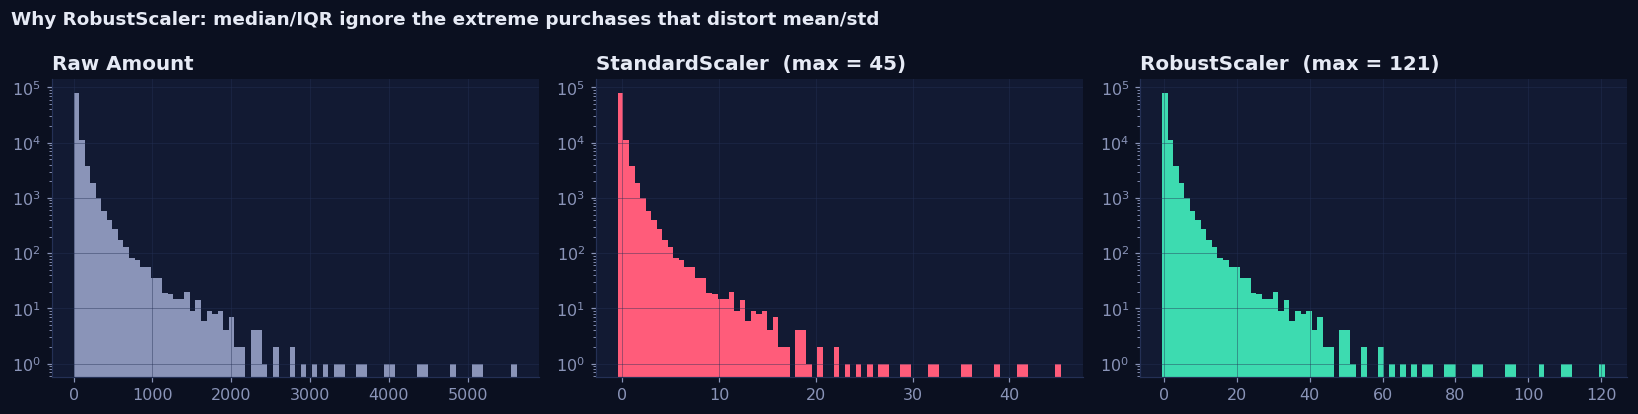

In [6]:
viz.plot_scaling_comparison(df); plt.show()

In [7]:
# The mechanics, spelled out on Amount:
q1, med, q3 = df.Amount.quantile([.25, .5, .75])
manual = (df.Amount - med) / (q3 - q1)
sk = RobustScaler().fit_transform(df[["Amount"]]).ravel()
print(f"median={med:.2f}  IQR={q3 - q1:.2f}  | manual == sklearn: {np.allclose(manual, sk)}")

median=22.25  IQR=46.25  | manual == sklearn: True


### 1.5 Leakage-free split
* stratified train / test split → **only normal rows** are used for training (unsupervised strategy)
* normal training rows are split again into a **fit set** and a **calibration set** (used to set the alert threshold – no fraud labels needed)
* the `RobustScaler` is fitted on the fit set only

In [8]:
split = preprocess(df, cfg)
print(f"fit (normal only): {len(split.X_fit):,} | calibration (normal only): {len(split.X_calib):,} | "
      f"test: {len(split.X_test):,} of which fraud = {int(split.y_test.sum())}")
split.X_fit[["Time", "Amount", "V1", "V2"]].describe().T

fit (normal only): 55,832 | calibration (normal only): 13,958 | test: 30,000 of which fraud = 90


,count,mean,std,min,25%,50%,75%,max
Time,55832.0,-2.639e-02,0.548,-1.013,-0.538,0.000,0.462,0.995
Amount,55832.0,7.231e-01,2.714,-0.485,-0.292,0.000,0.708,112.077
V1,55832.0,1.050e-02,1.977,-20.456,-1.144,0.018,1.166,24.457
V2,55832.0,4.920e-04,1.831,-18.077,-1.075,0.005,1.078,19.589


### 1.6 Which PCA features carry the fraud signal?

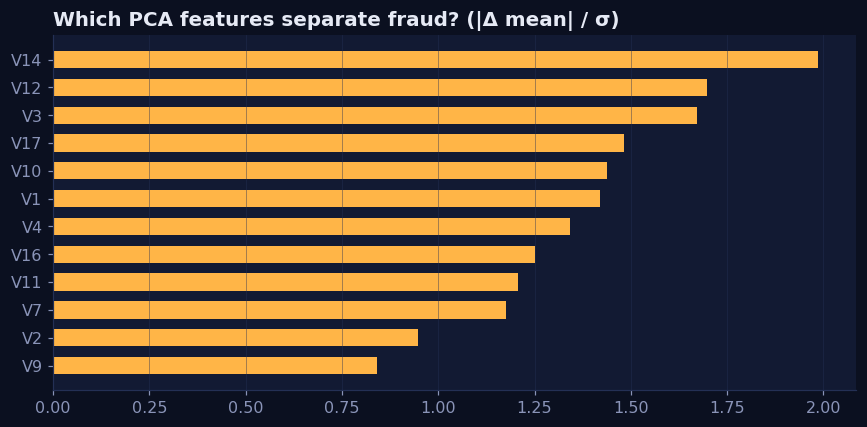

In [9]:
viz.plot_feature_separation(feature_separation(df, top=12)); plt.show()

## Phase 2 — Unsupervised model building
### 2.1 Isolation Forest — *"few and different"*
Random trees isolate a point by repeatedly choosing a random feature and split value. Anomalies sit alone in sparse space, so they
need **fewer splits** (short path length) → higher anomaly score. We fit on **normal data only**.

In [10]:
iforest = IsolationForest(n_estimators=200, max_samples=512, contamination="auto", n_jobs=-1, random_state=42)
t0 = time.perf_counter(); iforest.fit(split.X_fit); t_fit = time.perf_counter() - t0
if_scores = -iforest.score_samples(split.X_test)            # flip sign: higher = more anomalous
print(f"fit in {t_fit:.2f}s | PR-AUC = {average_precision_score(split.y_test, if_scores):.3f}")

fit in 0.53s | PR-AUC = 0.580


**Hyper-parameter experiment — `n_estimators`.** More trees stabilise the score; returns diminish quickly.

In [11]:
rows = []
for n in [25, 50, 100, 200, 400]:
    m = IsolationForest(n_estimators=n, max_samples=512, n_jobs=-1, random_state=42)
    t0 = time.perf_counter(); m.fit(split.X_fit); dt = time.perf_counter() - t0
    rows.append({"n_estimators": n, "fit_s": dt, "PR-AUC": average_precision_score(split.y_test, -m.score_samples(split.X_test))})
pd.DataFrame(rows)

,n_estimators,fit_s,PR-AUC
0,25,0.089,0.350
1,50,0.114,0.428
2,100,0.231,0.563
3,200,0.602,0.580
4,400,0.977,0.587


**Hyper-parameter experiment — `contamination`.** Contamination is the expected share of flagged traffic. Because we train on
normal data, we turn it into a threshold by taking the `(1 − c)` quantile of **calibration scores**: the false-positive rate then lands close to `c`.

In [12]:
from sentinelpay.models import threshold_from_contamination
from sentinelpay.evaluation import metrics_at_threshold
cal_scores = -iforest.score_samples(split.X_calib)
rows = []
for c in [0.001, 0.005, 0.01, 0.02, 0.05]:
    thr = threshold_from_contamination(cal_scores, c)
    m = metrics_at_threshold(split.y_test, if_scores, thr)
    rows.append({"contamination": c, "recall": m["recall"], "precision": m["precision"], "f1": m["f1"], "false alarms": m["fp"], "FPR": m["fpr"]})
pd.DataFrame(rows)

,contamination,recall,precision,f1,false alarms,FPR
0,0.001,0.578,0.591,0.584,36,0.001
1,0.005,0.656,0.296,0.408,140,0.005
2,0.010,0.711,0.183,0.292,285,0.010
3,0.020,0.789,0.115,0.201,546,0.018
4,0.050,0.856,0.049,0.093,1490,0.050


### 2.2 Local Outlier Factor — *density vs. neighbours*
LOF compares the local density around a point to the density around its `k` nearest neighbours. A point in a much sparser region than
its neighbours gets a score ≫ 1. `novelty=True` lets us **fit on normal data and score new transactions**.
LOF is neighbour-search based, so training rows are capped (`lof_max_train`).

In [13]:
fit_sample = split.X_fit.sample(cfg.lof_max_train, random_state=42)
lof = LocalOutlierFactor(n_neighbors=35, novelty=True, n_jobs=-1)
t0 = time.perf_counter(); lof.fit(fit_sample); l_fit = time.perf_counter() - t0
t0 = time.perf_counter(); lof_scores = -lof.score_samples(split.X_test); l_score = time.perf_counter() - t0
print(f"fit {l_fit:.2f}s | score {l_score:.2f}s | PR-AUC = {average_precision_score(split.y_test, lof_scores):.3f}")

fit 1.96s | score 2.95s | PR-AUC = 0.287


In [14]:
rows = []
for k in [10, 20, 35, 60, 100]:
    m = LocalOutlierFactor(n_neighbors=k, novelty=True, n_jobs=-1).fit(fit_sample)
    rows.append({"n_neighbors": k, "PR-AUC": average_precision_score(split.y_test, -m.score_samples(split.X_test))})
pd.DataFrame(rows)

,n_neighbors,PR-AUC
0,10,0.321
1,20,0.302
2,35,0.287
3,60,0.248
4,100,0.196


### 2.3 Side by side (plus a rank-fusion ensemble) via the reusable pipeline

In [15]:
res = run_pipeline(cfg)                                    # same models as above + calibration + fusion
cmp = pd.DataFrame({n: {"PR-AUC": res.pr[n].average_precision, "ROC-AUC": res.pr[n].roc_auc, "Fit (s)": m.fit_time,
                        "Score test (s)": m.score_time, "Latency (ms/txn)": m.latency_ms_per_txn}
                    for n, m in res.models.items()}).T
cmp

,PR-AUC,ROC-AUC,Fit (s),Score test (s),Latency (ms/txn)
Isolation Forest,0.580,0.974,0.415,0.269,0.009
Local Outlier Factor,0.287,0.979,1.851,2.856,0.095
Fusion (IF + LOF),0.590,0.982,2.266,3.125,0.104


LOF scoring is much slower than Isolation Forest, and the gap widens as the data grows.


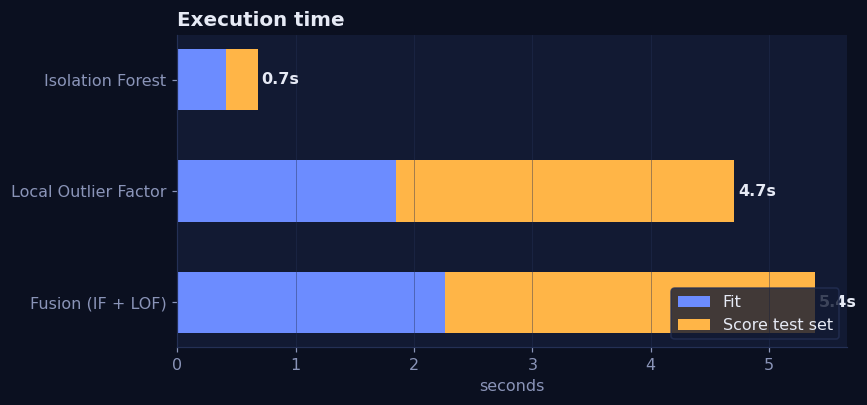

In [16]:
viz.plot_runtime(res.models); plt.show()
print("LOF scoring is much slower than Isolation Forest, and the gap widens as the data grows.")

## Phase 3 — Evaluation & threshold tuning
Accuracy is banned. We use **precision** (share of alerts that are fraud) and **recall** (share of fraud caught).
* **Scenario A – high threshold:** high precision, low recall → few false alarms, missed fraud.
* **Scenario B – low threshold:** low precision, high recall → catches fraud, challenges many legitimate customers.

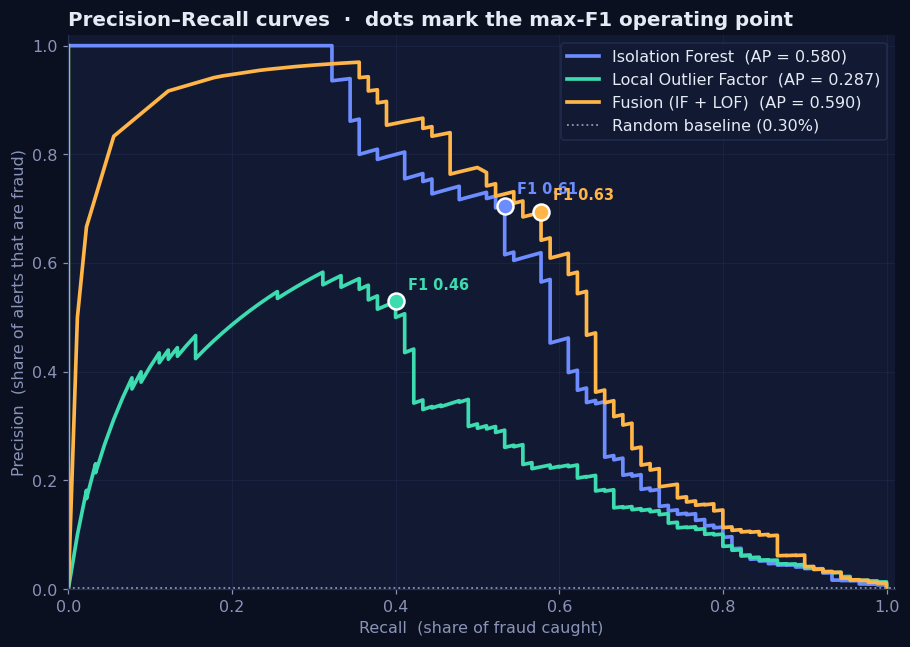

,score threshold,precision,recall,f1
Isolation Forest,0.473,0.706,0.533,0.608
Local Outlier Factor,1.686,0.529,0.400,0.456
Fusion (IF + LOF),2.563,0.693,0.578,0.630


In [17]:
y = split.y_test
viz.plot_pr_curves(res.pr, y); plt.show()
pd.DataFrame({n: p.best for n, p in res.pr.items()}).T.rename(columns={"threshold": "score threshold"})

### Contamination sweep — the business trade-off

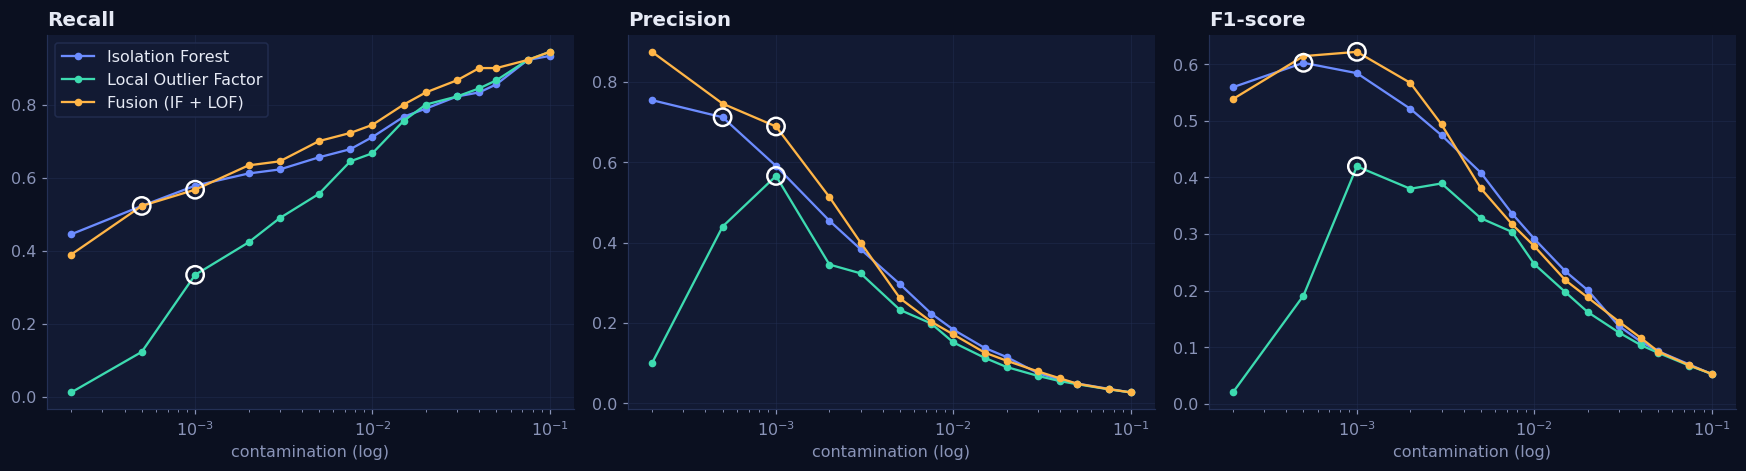

In [18]:
viz.plot_contamination_sweep(res.sweeps, {n: res.recs[n]["max_f1"]["contamination"] for n in res.models}); plt.show()

In [19]:
best = res.headline["model"]
res.sweeps[best][["contamination", "precision", "recall", "f1", "fp", "fn", "fpr", "total_cost"]].round(4)

,contamination,precision,recall,f1,fp,fn,fpr,total_cost
0,2.000e-04,0.755,0.444,0.559,13,50,4.000e-04,2492.00
1,5.000e-04,0.712,0.522,0.603,19,43,6.000e-04,2040.13
2,1.000e-03,0.591,0.578,0.584,36,38,1.200e-03,1660.53
3,2.000e-03,0.455,0.611,0.521,66,35,2.200e-03,1720.08
4,3.000e-03,0.384,0.622,0.475,90,34,3.000e-03,1682.76
5,5.000e-03,0.296,0.656,0.408,140,31,4.700e-03,1700.91
6,7.500e-03,0.223,0.678,0.336,212,29,7.100e-03,1643.92
7,1.000e-02,0.183,0.711,0.292,285,26,9.500e-03,1783.25
8,1.500e-02,0.138,0.767,0.234,431,21,1.440e-02,1883.33
9,2.000e-02,0.115,0.789,0.201,546,19,1.830e-02,2093.18


### Confusion matrices — both models at their max-F1 operating point

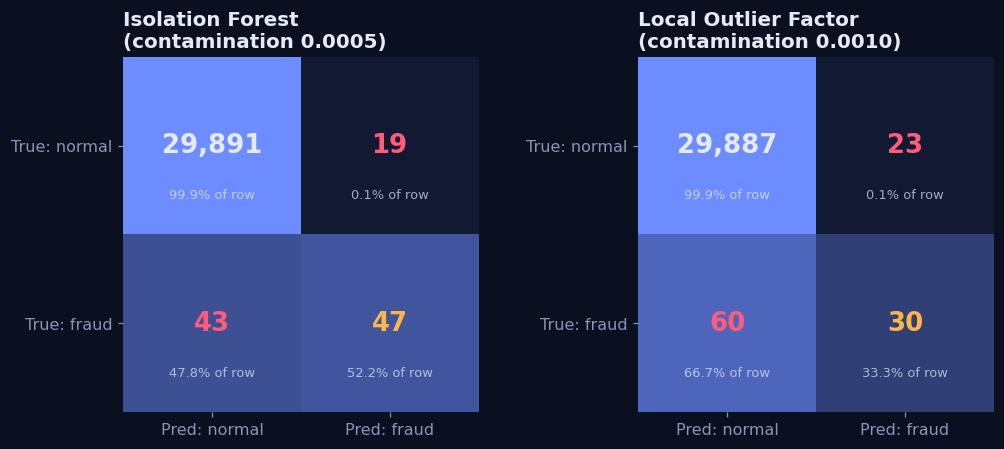

In [20]:
from sentinelpay.models import IFOREST, LOF
cms = {f"{n}\n(contamination {res.recs[n]['max_f1']['contamination']:.4f})": res.evaluate(n, res.recs[n]['max_f1']['contamination'])
       for n in (IFOREST, LOF)}
viz.plot_confusion_pair(cms); plt.show()

### Where do the detected anomalies sit? (PCA projection)

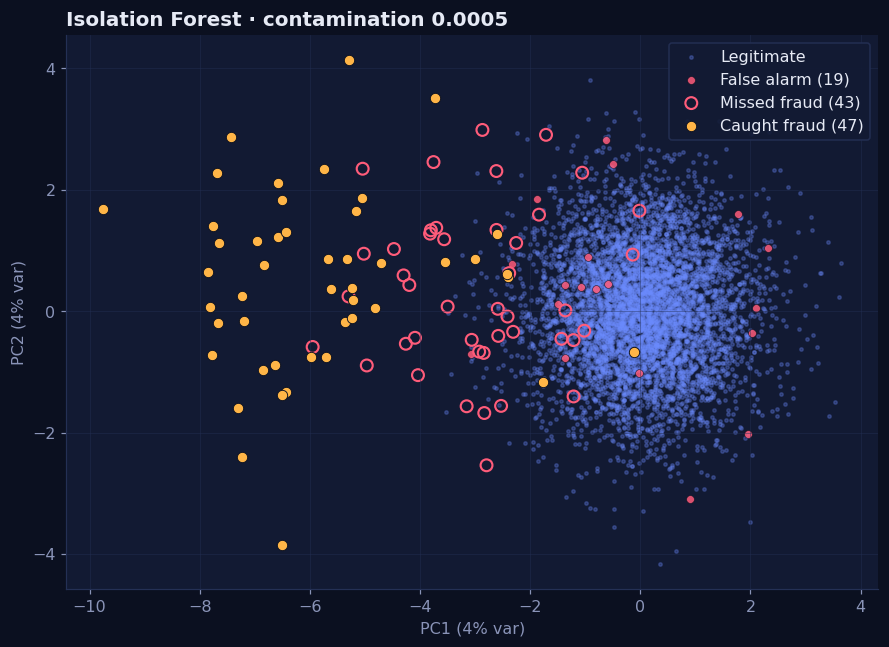

In [21]:
h = res.headline
pred = res.predictions(best, h["contamination"])
viz.plot_pca_scatter(split.X_test, y, pred, f"{best} · contamination {h['contamination']:.4f}"); plt.show()

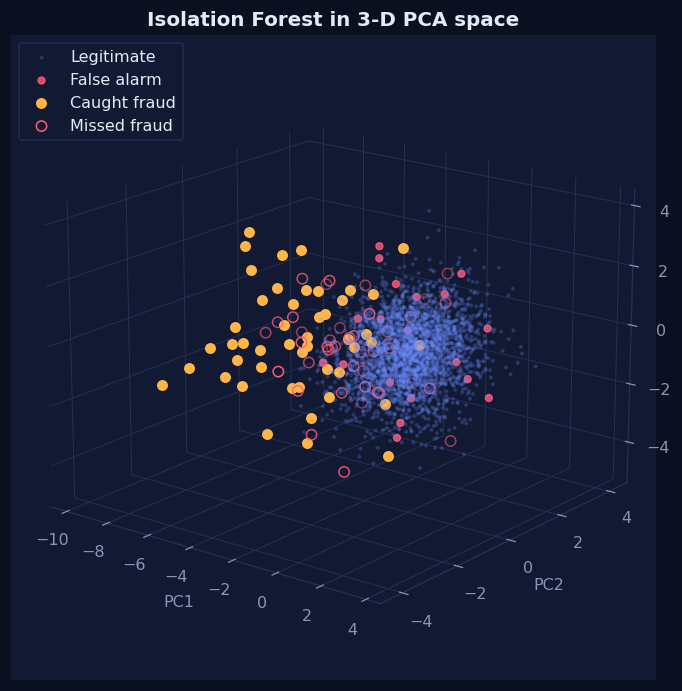

In [22]:
viz.plot_pca_3d(split.X_test, y, pred, f"{best} in 3-D PCA space"); plt.show()

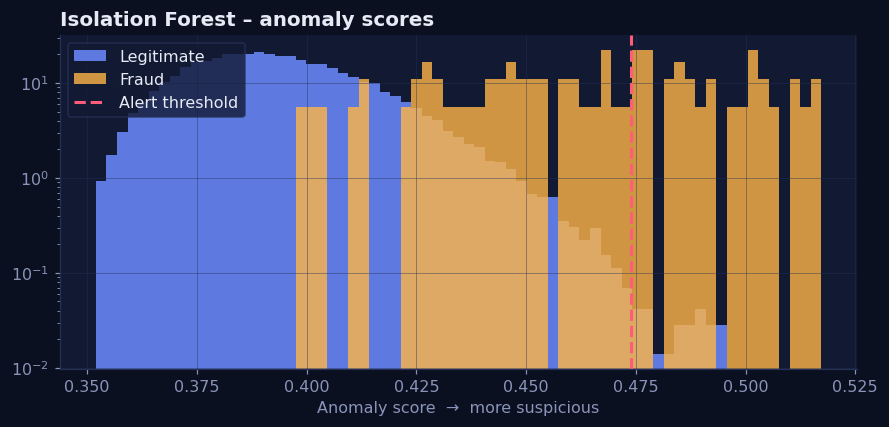

In [23]:
viz.plot_score_distribution(res.models[best].scores_test, y, res.evaluate(best, h["contamination"])["threshold"], f"{best} – anomaly scores"); plt.show()

## Recommendation

In [24]:
rec = res.recs[best]
for label, key in [("Balanced (max F1)", "max_f1"), ("Cost-optimal", "min_cost"), (f"Recall ≥ {cfg.target_recall:.0%}", "target_recall")]:
    r = rec.get(key)
    if r: print(f"{label:<22} contamination={r['contamination']:.4f}  recall={r['recall']:.0%}  precision={r['precision']:.0%}  "
                f"false alarms={int(r['fp'])}  FPR={r['fpr']:.2%}")
print(f"\nRecommendation: use {best} with contamination = {h['contamination']:.4f}.")

Balanced (max F1)      contamination=0.0005  recall=52%  precision=71%  false alarms=19  FPR=0.06%
Cost-optimal           contamination=0.0075  recall=68%  precision=22%  false alarms=212  FPR=0.71%
Recall ≥ 80%           contamination=0.0300  recall=82%  precision=7%  false alarms=913  FPR=3.05%

Recommendation: use Isolation Forest with contamination = 0.0005.


## GenAI analyst (NVIDIA API)
`sentinelpay.genai.NvidiaAnalyst` calls NVIDIA's OpenAI-compatible endpoint (`https://integrate.api.nvidia.com/v1`) to turn the top
anomalous features of an alert into a plain-English explanation and recommended action. It only receives anonymised PCA features and
scores. **Without `NVIDIA_API_KEY` it falls back to a rule-based explanation**, so this cell always runs.

In [25]:
from dotenv import load_dotenv; load_dotenv("../.env")
from sentinelpay.genai import NvidiaAnalyst, feature_deviations, risk_band
analyst = NvidiaAnalyst()
mm = res.models[best]; i = int(np.argmax(mm.scores_test))
pct = float((mm.scores_calib < mm.scores_test[i]).mean() * 100)
case = {"model": best, "anomaly_score": round(float(mm.scores_test[i]), 3), "score_percentile": round(pct, 3), "risk_band": risk_band(pct),
        "amount": float(split.raw_test.Amount[i]), "hour_of_day": round(float(split.raw_test.Time[i] % 86400 / 3600), 1),
        "deviations": feature_deviations(split.X_test.iloc[i], split.X_fit)}
text, src = analyst.explain_transaction(case)
print(f"[source: {src}]\n"); print(text)

[source: offline]

**Verdict:** CRITICAL risk – scores higher than 100.00% of normal traffic.

**Why it stands out:** Largest deviations from normal behaviour: Amount (+18.4σ), V3 (-5.0σ), V2 (+4.5σ). Amount $647.49 at hour 7.4.

**Recommended action:** block.

**Confidence caveat:** Rule-based summary (NVIDIA analyst offline); an anomaly is not proof of fraud.


---
**Next steps:** run on the real Kaggle dataset (`data/creditcard.csv`), validate thresholds on a time-based hold-out, add drift monitoring,
and serve scores via the Streamlit dashboard (`streamlit run app/dashboard.py`).